In [56]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Problem Statement**

### **Business Context**

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval.


### **Objective**

* To facilitate the process of visa approvals.
* To recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.

* This is a **binary classification** problem. The target variable is **case_status**.



### **Data Dictionary**

1. **case_id:** ID of each visa application
2. **continent** Information of continent the employee
3. **education_of_employee:** Information of education of the employee
4. **has_job_experience:** Does the employee has any job experience? Y= Yes; N = No
5. **requires_job_training::** Does the employee require any job training? Y = Yes; N = No.
6. **no_of_employees:** Number of employees in the employer's company
7. **yr_of_estab:** Year in which the employer's company was established
8. **region_of_employment:** Information of foreign worker's intended region of employment in the US.
9. **prevailing_wage:** Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
10. **unit_of_wage:** Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
11. **full_time_position:** Is the position of work full-time? Y = Full-Time Position; N = Part-Time Position
12. **case_status:** Flag indicating if the Visa was certified or denied

## **Installing and Importing the necessary libraries**

In [57]:
# to load and manipulate data
import pandas as pd
import numpy as np

# to visualize data
import matplotlib.pyplot as plt
import seaborn as sns

# To impute missing values
from sklearn.impute import SimpleImputer

# To do one-hot encoding
from sklearn.preprocessing import OneHotEncoder

# to split data into training and test sets
from sklearn.model_selection import train_test_split

# to build classification models
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier

# to build Decision Tree model
from sklearn.tree import DecisionTreeClassifier

# to import XGBoost
from xgboost import XGBClassifier

# to tune different models
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

# To get different performance metrics
import sklearn.metrics as metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    recall_score,
    accuracy_score,
    precision_score,
    f1_score,
)

# To undersample and oversample the data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# To suppress warnings
import warnings
warnings.filterwarnings("ignore")

## **Loading the dataset**

In [58]:
# loading data into a pandas dataframe
data = pd.read_csv("/content/drive/MyDrive/PythonCourse/Advanced_Machine_Learning/Project/EasyVisa.csv")

**Creating a copy of data**

In [59]:
# create a copy of the data to avoid permanent changes in original data
df = data.copy()

## **Data Overview**

**View the first 5 and last 5 rows of the dataset**

In [60]:
# First 5 rows
df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [61]:
# Last 5 rows
df.tail()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.57,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.79,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.85,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.77,Year,Y,Certified
25479,EZYV25480,Asia,Bachelor's,Y,N,3195,1960,Midwest,70876.91,Year,Y,Certified


**Shape of the dataset**

In [62]:
# checking no. of rows & columns in data
df.shape

(25480, 12)

**Observations:**

*   The dataset has 25480 rows and 12 columns.



**Checking the types of attributes in the dataset**

In [63]:
# checking attribute types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


**Observations:**

* **case_status is the target variable** which indicates whether a customer will be given visa or not.
* Only three variables are of numerical type, rest all are of object type.
* The object type variables can be converted to categorical type.
* **yr_of_estab** is of numerical type but it represents the year in which the company was established, hence should be in datetime format.


In [64]:
# convert object type to categorical
for col in df.columns:
  if df[col].dtype == 'object':
    df[col] = df[col].astype('category')

# rechecking data type
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   case_id                25480 non-null  category
 1   continent              25480 non-null  category
 2   education_of_employee  25480 non-null  category
 3   has_job_experience     25480 non-null  category
 4   requires_job_training  25480 non-null  category
 5   no_of_employees        25480 non-null  int64   
 6   yr_of_estab            25480 non-null  int64   
 7   region_of_employment   25480 non-null  category
 8   prevailing_wage        25480 non-null  float64 
 9   unit_of_wage           25480 non-null  category
 10  full_time_position     25480 non-null  category
 11  case_status            25480 non-null  category
dtypes: category(9), float64(1), int64(2)
memory usage: 2.0 MB


* All the object type variables are now coverted to categorical variables.

**Checking for duplicates in the dataset**

In [65]:
df.duplicated().sum() # get count of duplicates rows

np.int64(0)

**Observations:**

* There are no duplicates in the data.

**Statistical summary of the data**

In [66]:
df.describe().T # getting descriptive statistics of the data & transpose

,count,mean,std,min,25%,50%,75%,max
no_of_employees,25480.0,5667.043210,22877.928848,-26.0000,1022.00,2109.00,3504.0000,602069.00
yr_of_estab,25480.0,1979.409929,42.366929,1800.0000,1976.00,1997.00,2005.0000,2016.00
prevailing_wage,25480.0,74455.814592,52815.942327,2.1367,34015.48,70308.21,107735.5125,319210.27


**Observations:**

*  **no_of_employees:**

    *  The average no of employees is approximately 5700.
    *  There are some small scale companies with around 26 employees.
    *  No. of employees is negative in some companies which needs to be corrected.

*  **yr_of_estab:** Most of the companies were established in the 1900s.
*  **prevailing_wage:**

    * On average, employees are paid approximately $75K.
     Some employees earn as low as $2 while some are paid as high as $319K.









**Checking the distribution of categories in categorical variables**



In [67]:
for col in df.columns:
  if df[col].dtype == 'category':
    print(df[col].value_counts(1))
    print("*" * 50)

case_id
EZYV9999     0.000039
EZYV01       0.000039
EZYV02       0.000039
EZYV03       0.000039
EZYV04       0.000039
               ...   
EZYV10000    0.000039
EZYV1000     0.000039
EZYV100      0.000039
EZYV10       0.000039
EZYV09       0.000039
Name: proportion, Length: 25480, dtype: float64
**************************************************
continent
Asia             0.661735
Europe           0.146468
North America    0.129199
South America    0.033438
Africa           0.021625
Oceania          0.007535
Name: proportion, dtype: float64
**************************************************
education_of_employee
Bachelor's     0.401648
Master's       0.378100
High School    0.134223
Doctorate      0.086028
Name: proportion, dtype: float64
**************************************************
has_job_experience
Y    0.580926
N    0.419074
Name: proportion, dtype: float64
**************************************************
requires_job_training
N    0.884027
Y    0.115973
Name: proportion, 

**Observations:**

* All the values are in the **case_id** column are unique. This column can be dropped as it does not add any relevant information to the analyses.
* Most of the employees are from **Asia** **(~66%)**, followed by **Europe (~15%)**.
* Most employees have a **Bachelor's (~40%)** or **Master's (~38%)** degree.
* Around **58 % of the employees have prior job experience**.
* Most of the employees **(~88%) do not require job training**.
* Most **wages are reported yearly (~90%)**.
* Around **89% of positions are full-time**.
* **~67% visa cases are Certified**, while **~33% are denied**.

## **Exploratory Data Analyses (EDA)**

### **Univariate Analyses**

**Univariate Analysis of Continuous Attributes - Histograms**




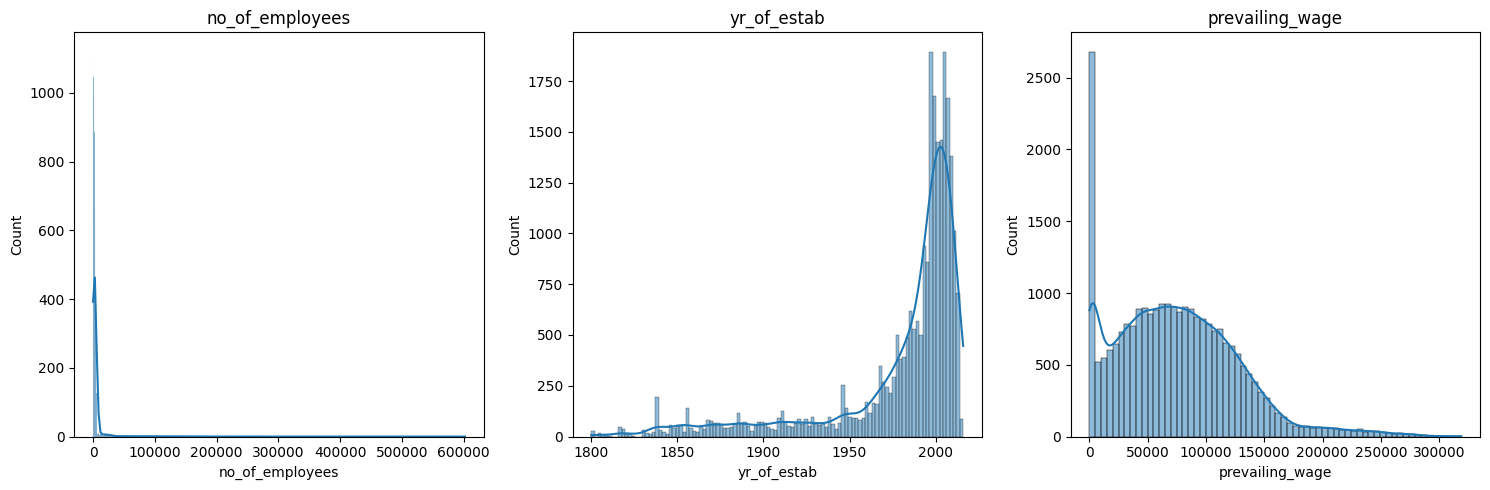

In [68]:
# defining the figure size
plt.figure(figsize=(15, 5))

# defining continous numerical features
num_cols = ['no_of_employees', 'yr_of_estab', 'prevailing_wage']

# creating histograms
for i, col in enumerate(num_cols):
  plt.subplot(1, 3, i+1)
  sns.histplot(data = df, x = col, kde=True)
  plt.title(col)

plt.tight_layout()
plt.show()


**Observations:**

**`no_of_employees`**
* The distribution is highly right-skewed.
* Most of the companies have a small of number of employees, except a few with very large number of employees.

**`yr_of_estab`**
* The distribution is left-skewed, with most of the companies established after 1950.
* A large number of companies were established between 1980-2010.
* A very few companies were established before 1900s.

**`prevailing_wage`**
* The distribution is right-skewed.
* Most of the wages paid to the employees were between $30,000-$120,000.




**Univariate Analysis of Categorical Attributes - Countplots**

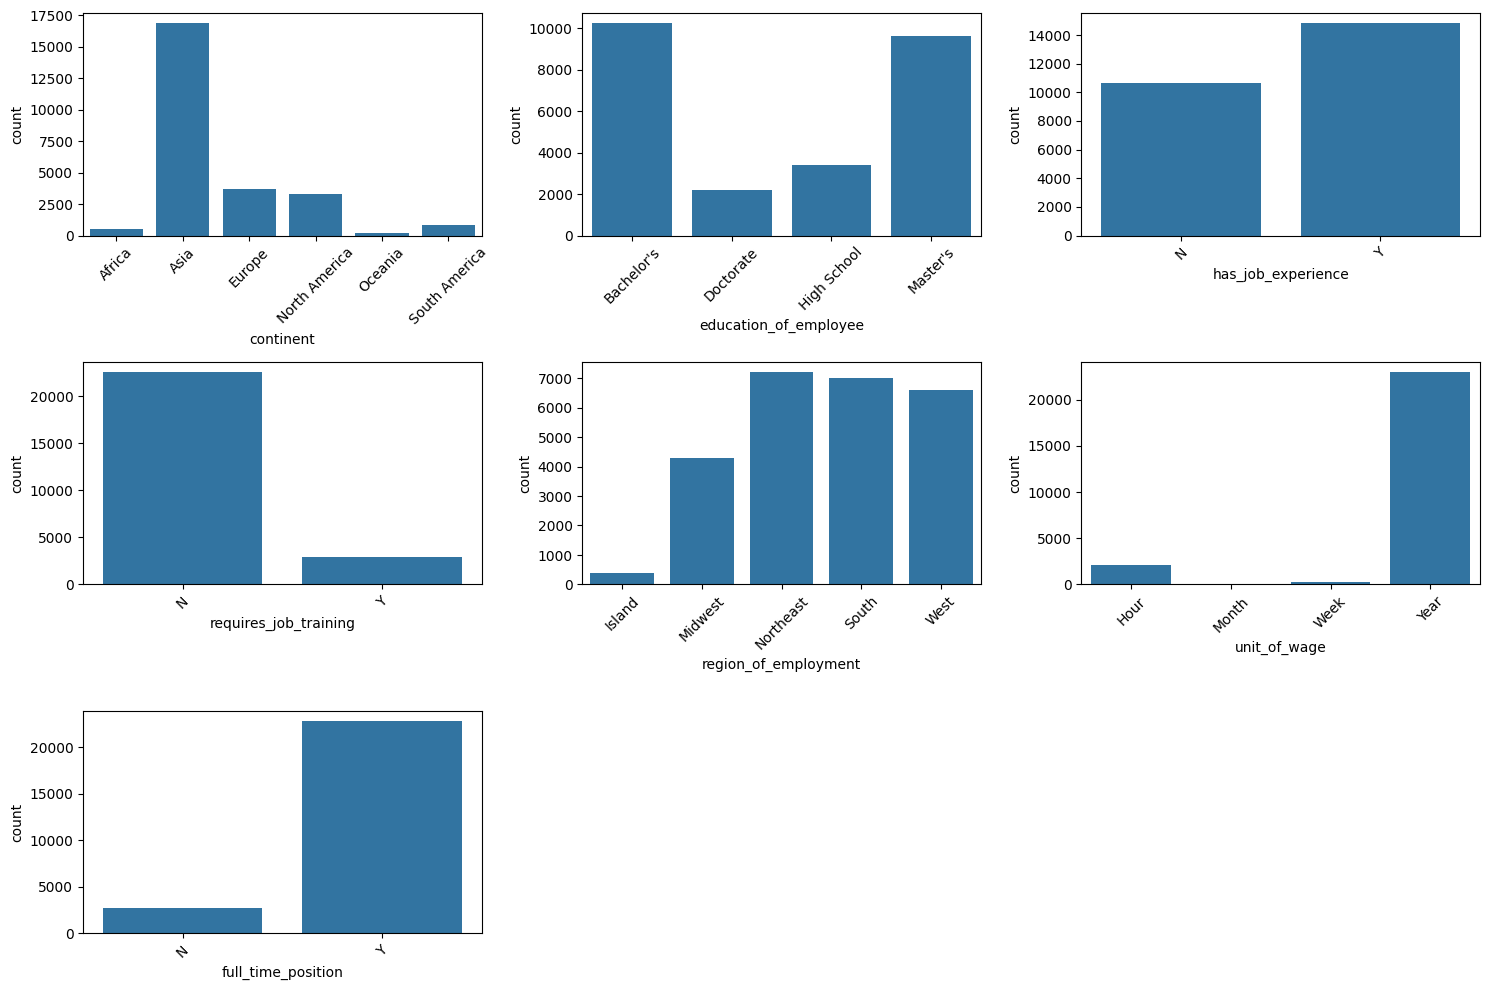

In [69]:
# defining the figure size
plt.figure(figsize=(15, 10))

# defining categorical features
cat_cols = ['continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'region_of_employment', 'unit_of_wage', 'full_time_position']

# creating countplot
for i, col in enumerate(cat_cols):
  plt.subplot(3, 3, i+1)
  sns.countplot(data = df, x = col)
  plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Observations:**

**`continent`**
* Most of the visa applications were from Asia, followed by Europe and North America.

**`education_of_employee`**
* Most of the employees hold Bachelor's or Master's degrees.

**`has_job_experience`**
* A large number of employees have prior job experience.

**`requires_job_training`**
* Most of the employees do not require job training as compared to those who do not have the required skills.

**`region_of_employment`**
* The intended region of employment is Northeast region, followed by South and West.

**`unit_of_wage`**
* Most of the wages are reported on a yearly basis.

**`full_time_position`**
* Majority of the job positions are full time.

**`case_status`**
* Most of the visa applications are certified, while a smaller number of applications are denied.






### **Bivariate Analyses**

**Correlation Analysis**

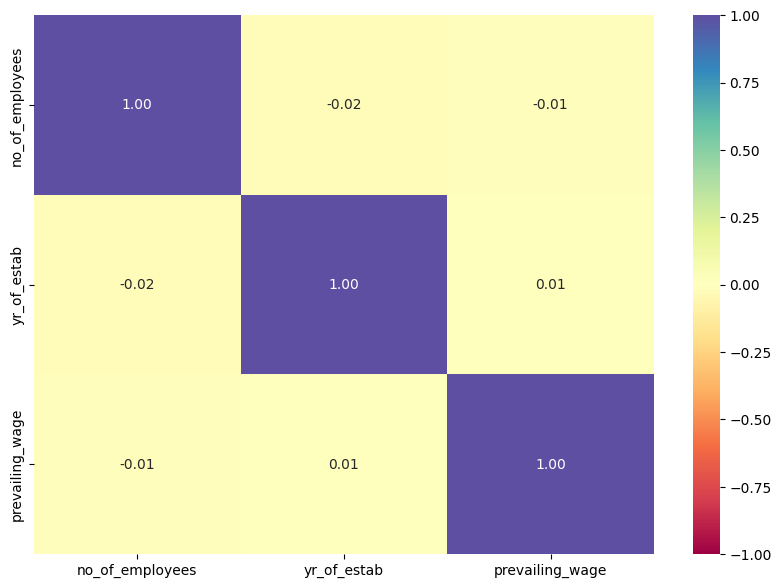

In [70]:
# defining the figure size
plt.figure(figsize=(10, 7))

# plotting the correlation heatmap
sns.heatmap(df.corr(numeric_only = True), annot=True, vmin=-1, vmax=1, fmt='0.2f', cmap='Spectral');

**Observation:**

* The correlation values between **no_of_employees**, **yr_of_estab** and **prevailing_wage** is very close to zero, indicating little to no relationship between these variables .
* These variables are independent of each other.

**Numerical variables vs Target variable**

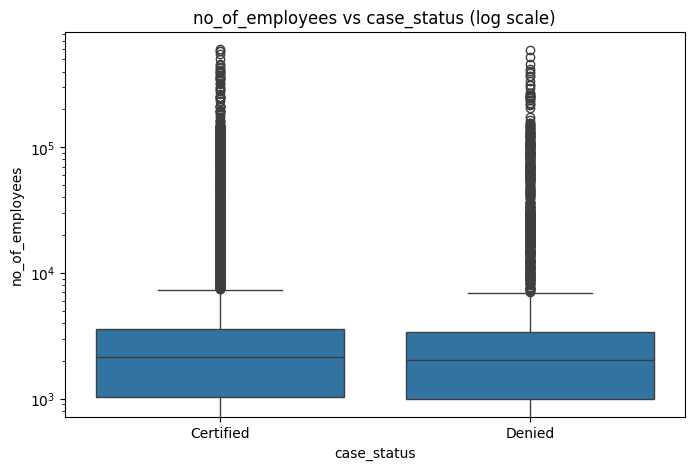

In [71]:
# Boxplot of no_of_employees vs case_status
plt.figure(figsize=(8,5))
sns.boxplot(x='case_status', y='no_of_employees', data=df)
plt.yscale('log')
plt.title('no_of_employees vs case_status (log scale)')
plt.show()

**Observations:**

* The median number of employees for certified cases is slightly higher than denied cases.
* Both categories have outliers indicating some companies with very large employee counts.
* The overall distribution of certified and denied cases is very similar indicating no_of_employees does not influence case_status.




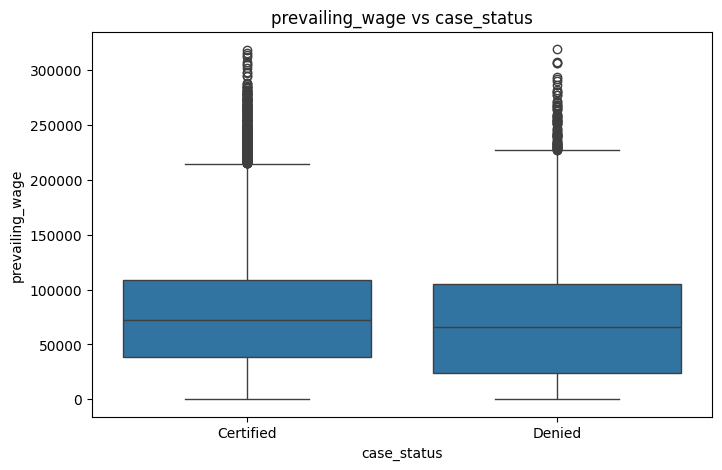

In [72]:
# Boxplot of prevailing_wage vs case_status
plt.figure(figsize=(8,5))
sns.boxplot(x='case_status', y='prevailing_wage', data=df)
plt.title('prevailing_wage vs case_status')
plt.show()

**Observations:**

* The median of prevailing wage is slightly higher for ceritified cases compared to denied.
* The wage distribution is higher for certified cases, although both categories show extreme upper outliers.
* This indicates that jobs offering higher wages tend to be associated with certified cases.

**Categorical variables vs Target variable**

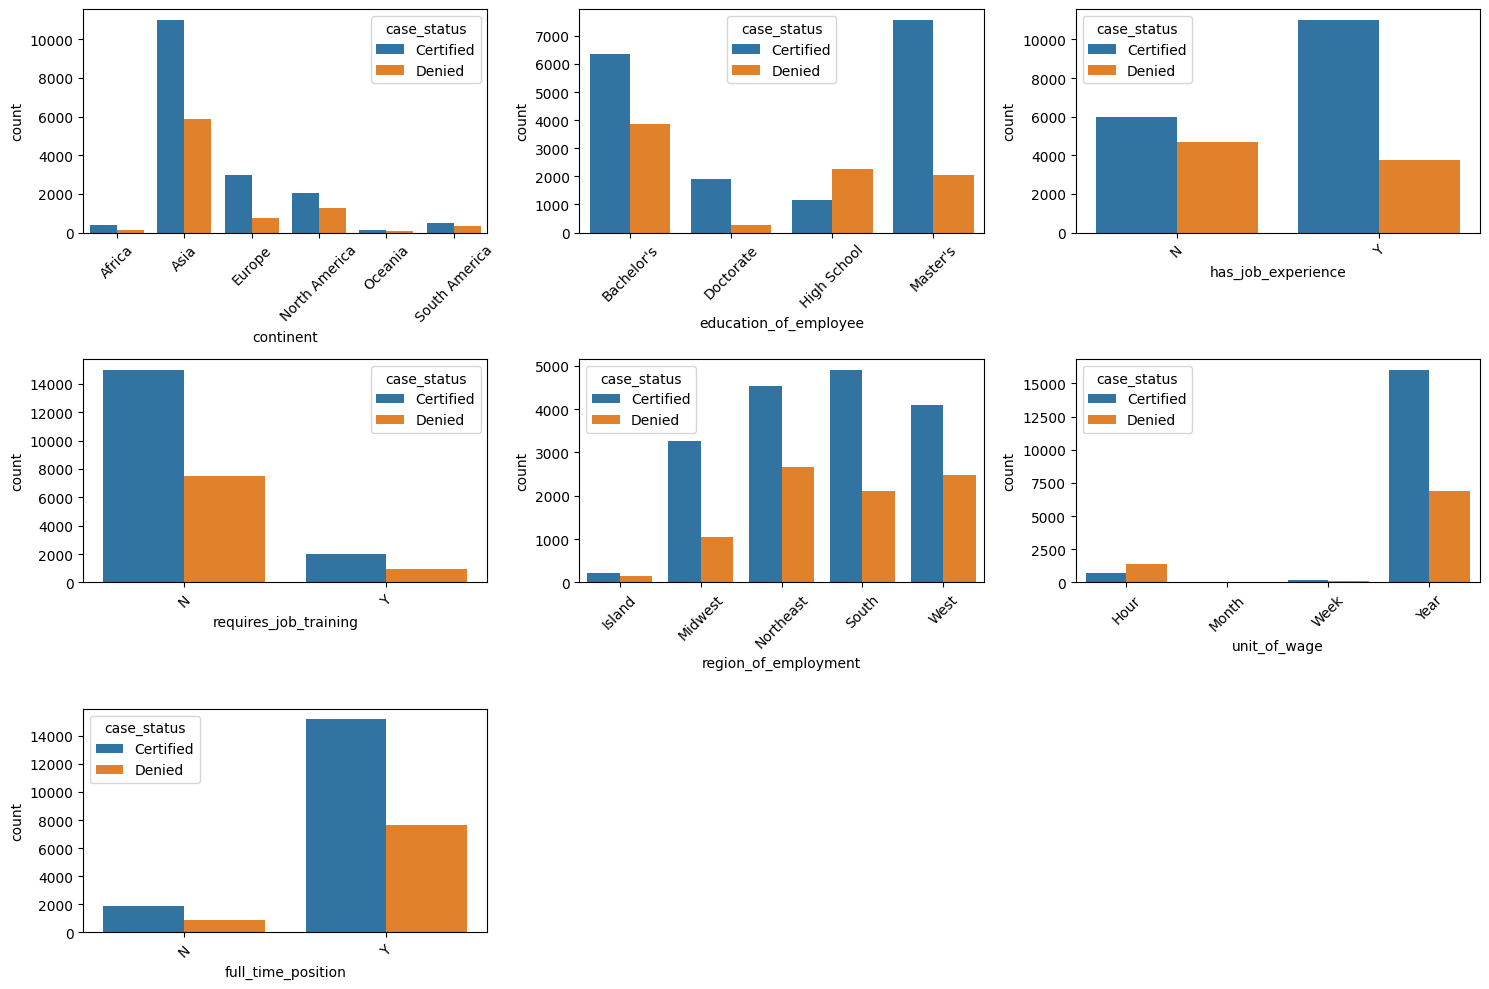

In [73]:
# defining the figure size
plt.figure(figsize=(15, 10))

# defining categorical features
cat_cols = ['continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'region_of_employment', 'unit_of_wage', 'full_time_position']

# creating countplot
for i, col in enumerate(cat_cols):
  plt.subplot(3, 3, i+1)
  sns.countplot(data = df, x = col, hue = 'case_status')
  plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Observations:**

**`continent`**
* Most of the visa applications are from Asia and a large number of these are Certified.

**`education_of_employee`**
* Employees holding Bachelor's, Master's  and Doctoral degrees have high number of visa certifications.

**`has_job_experience`**
* Employees with prior job experience have a siginificantly higher number of visa certifications.

**`requires_job_training`**
* Most of the employees do not require job training and have higher number of ceritifications.

**`region_of_employment`**
* Most of the certified cases are from South region followed by Northeast, West and Midwest .

**`unit_of_wage`**
* Most of the wages are reported on a yearly basis, and these show higher number of certified cases.

**`full_time_position`**
* The full time job positions have significantly higher number of visa certifications.



#### **Pairwise Relationships Among Numerical Variables Colored by case_status**

<Figure size 1200x800 with 0 Axes>

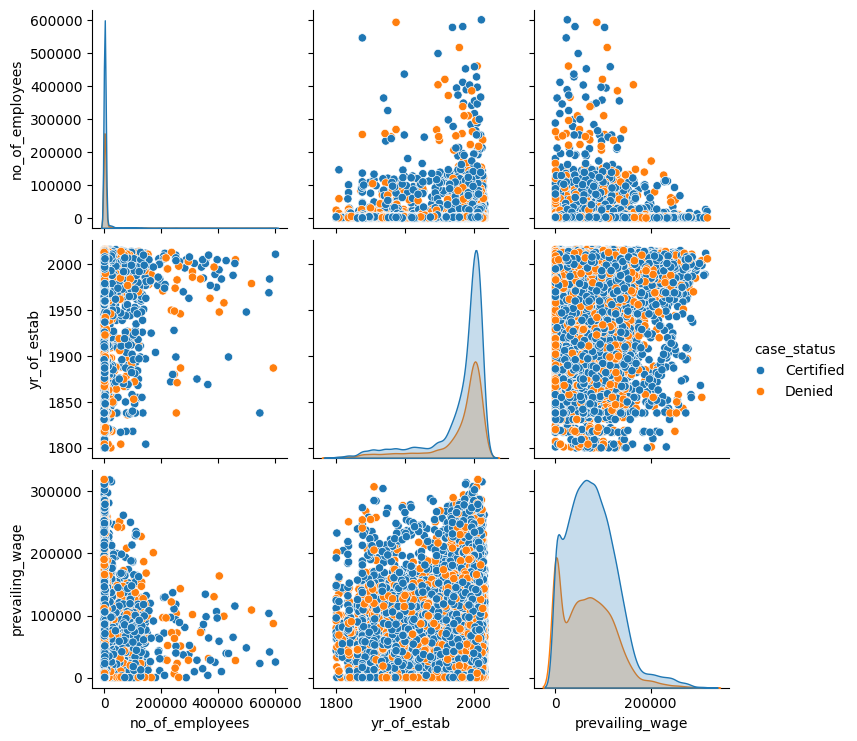

In [74]:
# Scatter plot matrix
plt.figure(figsize=(12, 8))
sns.pairplot(df, vars=num_cols, hue='case_status', diag_kind='kde')
plt.show()

**Observations:**

* The scatter plot shows no strong relationship between numerical variables.
* There is a strong overlap in points representing certified and denied cases indicating numerical variables do not clearly separate the visa certification status.



### **Key Insights from EDA**

*   Most visa applicants have high education level, mostly a Bachelors and Masters degree suggesting the importance of higher education in visa approval.
*   A majority of applicants have prior job experience, suggesting experienced professionals are more likely apply for employment visa.
*   Most of the jobs offer full-time positions indicating employer commitment.
*   Certain regions have higher employement demand which may impact visa certification.
*   The distribution of wages is highly skewed indicating some companies pay very high salaries for specialized roles.




## **Data Pre-processing**

**Missing value treatment**

In [75]:
df.isnull().sum() # getting count of null values in columns

,0
case_id,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0


**Observations:**

* There are no missing values in the data, so no treatment is required.





**Outlier detection & Treatment**

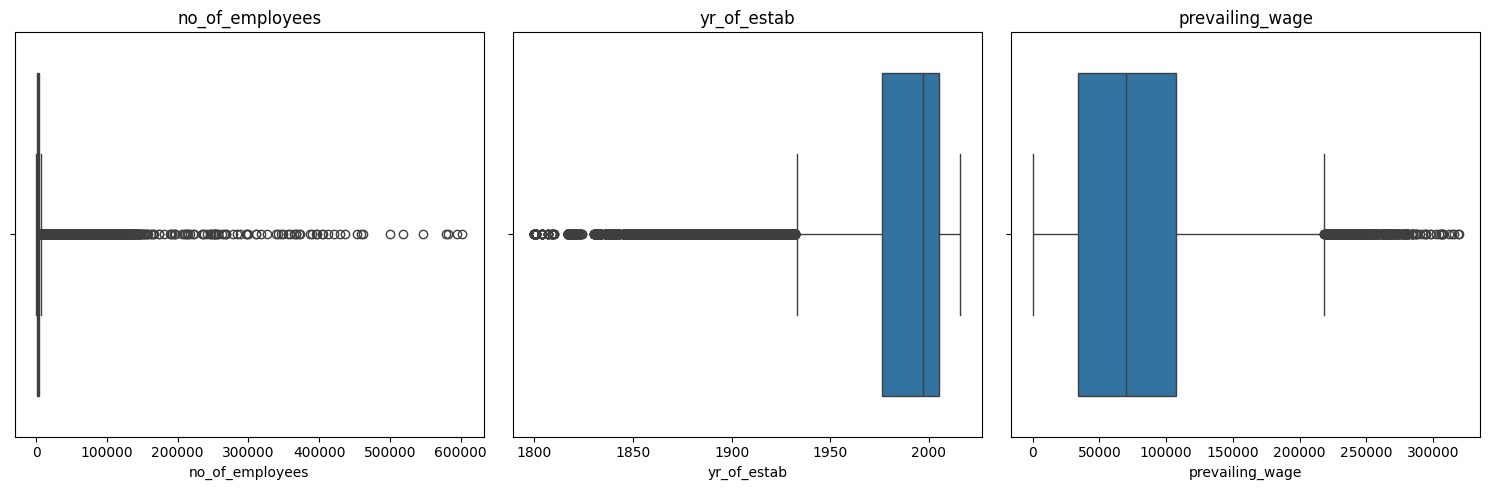

In [76]:
# defining the figure size
plt.figure(figsize=(15, 5))

# creating histograms
for i, col in enumerate(num_cols):
  plt.subplot(1, 3, i+1)
  sns.boxplot(data = df, x = col)
  plt.title(col)

plt.tight_layout()
plt.show()

**Observations:**

**`no_of_employees`**
* A large number of extreme outliers on the right side indicate that there are a few companies with a very large number of employees.

**`yr_of_estab`**
* Most of the companies were established in recent years, while a few companies were established before 1950 appearing as the left-side outliers.

**`prevailing_wage`**
* Several outliers on the right-side indicate some employees are paid significantly higher wages.


***All the outliers were retained because these are real-world values.***

**Handling negative values in no_of_employees**

In [77]:
# extracting columns with negative values in no_of_employees
df.loc[df['no_of_employees'] < 0].head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
245,EZYV246,Europe,Master's,N,N,-25,1980,Northeast,39452.99,Year,Y,Certified
378,EZYV379,Asia,Bachelor's,N,Y,-11,2011,Northeast,32506.14,Year,Y,Denied
832,EZYV833,South America,Master's,Y,N,-17,2002,South,129701.94,Year,Y,Certified
2918,EZYV2919,Asia,Master's,Y,N,-26,2005,Midwest,112799.46,Year,Y,Certified
6439,EZYV6440,Asia,Bachelor's,N,N,-14,2013,South,103.97,Hour,Y,Denied


In [78]:
# total number of columns with negative no_of_employees
df.loc[df['no_of_employees'] < 0].shape

(33, 12)

* There are 33 rows with negative value for no_of_employees column.
* The negative values can be the result of typing mistake, so we can replace them with positive values.



In [79]:
df['no_of_employees'] = df['no_of_employees'].abs() # replacing negative values with positive
df.describe() # re-check the data

,no_of_employees,yr_of_estab,prevailing_wage
count,25480.000000,25480.000000,25480.000000
mean,5667.089207,1979.409929,74455.814592
std,22877.917453,42.366929,52815.942327
min,11.000000,1800.000000,2.136700
25%,1022.000000,1976.000000,34015.480000
50%,2109.000000,1997.000000,70308.210000
75%,3504.000000,2005.000000,107735.512500
max,602069.000000,2016.000000,319210.270000


**Observations:**

* There are no negative values in no_of_employees.
* The minimum no_of_employees in a company is 11.

**Dropping the columns having unique values**




In [80]:
df['case_id'].nunique()

25480

* Since all the values in case_id column are unique, it will not contribute in model predictions and thus can be dropped.

In [81]:
# Dropping ID column
df.drop(columns = 'case_id', axis=1, inplace=True)

### **Feature Engineering**

**Encoding categorical variables**




In [82]:
# Label encoding

# mapping has_job_experience
df['has_job_experience'] = df['has_job_experience'].map({'Y': 1, 'N' : 0})
# mapping requires_job_training
df['requires_job_training'] = df['requires_job_training'].map({'Y': 1, 'N' : 0})
# mapping full_time_position
df['full_time_position'] = df['full_time_position'].map({'Y': 1, 'N' : 0})
# mapping case_status
df['case_status'] = df['case_status'].map({'Certified': 1, 'Denied' : 0})

df.head() # check the data

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,Asia,High School,0,0,14513,2007,West,592.2029,Hour,1,0
1,Asia,Master's,1,0,2412,2002,Northeast,83425.6500,Year,1,1
2,Asia,Bachelor's,0,1,44444,2008,West,122996.8600,Year,1,0
3,Asia,Bachelor's,0,0,98,1897,West,83434.0300,Year,1,0
4,Africa,Master's,1,0,1082,2005,South,149907.3900,Year,1,1


**Calculate company age**


In [83]:
df['company_age'] = df['yr_of_estab'].max() - df['yr_of_estab'] # calculate company age
df.drop('yr_of_estab', axis=1, inplace=True) # drop original column
df.head() # check the data


,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status,company_age
0,Asia,High School,0,0,14513,West,592.2029,Hour,1,0,9
1,Asia,Master's,1,0,2412,Northeast,83425.6500,Year,1,1,14
2,Asia,Bachelor's,0,1,44444,West,122996.8600,Year,1,0,8
3,Asia,Bachelor's,0,0,98,West,83434.0300,Year,1,0,119
4,Africa,Master's,1,0,1082,South,149907.3900,Year,1,1,11


**Observations:**

* The original column, 'yr_ef_estab' was dropped.
* A new column, 'company_age' was added.

**Standardize unit of wage**

In [84]:
df.loc[df['unit_of_wage'] == 'Hour', 'prevailing_wage'] *= 2080  # converting hourly age to yearly age
df.loc[df['unit_of_wage'] == 'Week', 'prevailing_wage'] *= 52  # converting weekly age to yearly age
df.loc[df['unit_of_wage'] == 'Month', 'prevailing_wage'] *= 12  # converting monthly age to yearly age

# drop unit_of_wage column
df.drop('unit_of_wage', axis = 1, inplace = True)

In [85]:
# check the data
df.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,region_of_employment,prevailing_wage,full_time_position,case_status,company_age
0,Asia,High School,0,0,14513,West,1231782.032,1,0,9
1,Asia,Master's,1,0,2412,Northeast,83425.650,1,1,14
2,Asia,Bachelor's,0,1,44444,West,122996.860,1,0,8
3,Asia,Bachelor's,0,0,98,West,83434.030,1,0,119
4,Africa,Master's,1,0,1082,South,149907.390,1,1,11


### **Data preparation for modeling**

**Defining the explanatory (independent) and response (dependent) variables**

In [86]:
X = df.drop(["case_status"], axis=1) # Features
y = df["case_status"] # Target variable

**Creating train, validation and test sets**





In [87]:
# Splitting the data into 80% temporary set and 20% test set
# stratify = y to ensure balanced distribution of target variable in train and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size = 0.20,
    stratify = y,
    random_state=42)

# Splitting the temporary data into 75% temporary set and 25% validation set
# stratify = y to ensure balanced distribution of target variable in train and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size = 0.25,
    stratify = y_temp,
    random_state=42)

In [88]:
# Number of rows in train, validation & test sets
print("Number of instances in train set:", X_train.shape[0])
print("Number of instances in validation set:", X_val.shape[0])
print("Number of instances in test set:", X_test.shape[0])

Number of instances in train set: 15288
Number of instances in validation set: 5096
Number of instances in test set: 5096


In [89]:
# Distribution of target variable, y in train, validation & test sets
print("Percentage of classes in train set:", y_train.value_counts(normalize=True)*100)
print("Percentage of classes in validation set:", y_val.value_counts(normalize=True)*100)
print("Percentage of classes in test set:", y_test.value_counts(normalize=True)*100)

Percentage of classes in train set: case_status
1    66.790947
0    33.209053
Name: proportion, dtype: float64
Percentage of classes in validation set: case_status
1    66.777865
0    33.222135
Name: proportion, dtype: float64
Percentage of classes in test set: case_status
1    66.797488
0    33.202512
Name: proportion, dtype: float64


**Create dummy variables**



In [90]:
X_train = pd.get_dummies(X_train, columns=["education_of_employee","continent","region_of_employment"], drop_first=True) # One-hot encoding in train set
X_train = X_train.astype(float)
X_val = pd.get_dummies(X_val, columns=["education_of_employee","continent","region_of_employment"], drop_first=True) # One-hot encoding in train set
X_val = X_val.astype(float)
X_test = pd.get_dummies(X_test, columns=["education_of_employee","continent","region_of_employment"], drop_first=True) # One-hot encoding in test set
X_test = X_test.astype(float)


In [91]:
X_train.head() # check train data

,has_job_experience,requires_job_training,no_of_employees,prevailing_wage,full_time_position,company_age,education_of_employee_Doctorate,education_of_employee_High School,education_of_employee_Master's,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America,region_of_employment_Midwest,region_of_employment_Northeast,region_of_employment_South,region_of_employment_West
24723,1.0,0.0,4591.0,51962.44,1.0,21.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
15992,0.0,0.0,2976.0,9745.90,1.0,30.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
23134,0.0,0.0,1205.0,55708.47,1.0,15.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
19092,1.0,0.0,1160.0,24098.93,1.0,131.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
16937,1.0,0.0,5669.0,48039.74,1.0,22.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [92]:
X_val.head() # check validation data

,has_job_experience,requires_job_training,no_of_employees,prevailing_wage,full_time_position,company_age,education_of_employee_Doctorate,education_of_employee_High School,education_of_employee_Master's,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America,region_of_employment_Midwest,region_of_employment_Northeast,region_of_employment_South,region_of_employment_West
24226,0.0,0.0,48.0,123656.77,1.0,8.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
9462,0.0,0.0,1385.0,53925.14,1.0,48.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
22047,1.0,1.0,1775.0,47429.39,1.0,16.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5107,1.0,0.0,4389.0,54583.99,1.0,16.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
22832,0.0,1.0,3241.0,18369.08,1.0,53.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [93]:
X_test.head() # check test data

,has_job_experience,requires_job_training,no_of_employees,prevailing_wage,full_time_position,company_age,education_of_employee_Doctorate,education_of_employee_High School,education_of_employee_Master's,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America,region_of_employment_Midwest,region_of_employment_Northeast,region_of_employment_South,region_of_employment_West
5795,1.0,0.0,4918.0,78424.77,1.0,13.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
20330,1.0,0.0,635.0,42786.52,1.0,9.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
7065,0.0,0.0,2219.0,89517.71,1.0,16.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4101,0.0,0.0,3994.0,171509.49,1.0,24.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1437,0.0,0.0,3120.0,61440.83,1.0,15.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [94]:
# Number of rows & columns in train, validation & test sets
print("Number of instances in train set:", X_train.shape)
print("Number of instances in validation set:", X_val.shape)
print("Number of instances in test set:", X_test.shape)

Number of instances in train set: (15288, 18)
Number of instances in validation set: (5096, 18)
Number of instances in test set: (5096, 18)


**Observations:**

* The dataset split is 60/20/20 % for train/validation/test sets.
* The proportion of target variable in train, validation and test set is 66% certified and 33% denied.
* The number of columns after encoding in all the datasets is 18.




## **Model Building**

### **Model Evaluation Criteria**





**What does OFLC want?**

* OFLC wants a classification model that can identify the candidates suitable for visa certification.

**Which case is more important?**

* Predicting an applicant should be denied visa but the applicant is suitable for visa certification. Missing a potential certified applicant will be a loss to the company.

**Most important metric**

* **Recall**: Proportion of actual positives which are predicted positives.
    * Crucial metric for visa certification prediction as high recall means less chances of missing certified cases.

**Other metrics**

* **Precision**: Proportion of predicted positives which are actual positives
    * Important to avoid predicting denied cases as certified, **supporting metric to recall**

* **F1 Score**: Harmonic mean of precision and recall
    * Maintains a balance between False positives and False negatives since precision drops when recall increases, **secondary metric to recall**




**Handling Class Imbalance**

Class imbalance can have a negative impact on model performance since model can be biased towards majority class.

Two strategies were explored to address this issue:

* **Oversampling (SMOTE)** – increase the instances of minority class by generating synthetic instances for it.
* **Undersampling** – reduces the instances from majority class to introduce a balance in class.

Models were trained on the **original, oversampled, and undersampled datasets** to evaluate in the impact of balancing techniques on predictive performance.

**Model Generation & Evaluation Function**

In [95]:
# creating the model instances
models = [] # an empty list to store model instances
models.append(("Decision Tree", DecisionTreeClassifier(random_state=42)))
models.append(("Random Forest", RandomForestClassifier(random_state=42)))
models.append(("Bagging Classifier", BaggingClassifier(random_state=42)))
models.append(("AdaBoost", AdaBoostClassifier(random_state=42)))
models.append(("XGBoost", XGBClassifier(random_state=42, eval_metric="logloss")))

In [96]:
# defining a function to generate models & compute metrics for performance evaluation
def model_performance_evaluation(models, X_train, y_train, X_val, y_val):
  '''
  Function to generate models & compute metrics for
  evaluation of performance of the
  generated classification model

  models: classifier
  X_train: features from train set
  y_train: target variable from train set
  X_val: features from validation set
  y_val: target variable from validation set
  '''
  results = [] # an empty list to store results

  for name, model in models:

    model.fit(X_train, y_train) # train the model
    train_preds = model.predict(X_train) # prediction on train set
    val_preds = model.predict(X_val) # prediction on validation set

    train_accuracy =  accuracy_score(y_train, train_preds)
    train_precision = precision_score(y_train, train_preds)
    train_recall = recall_score(y_train, train_preds)
    train_f1 = f1_score(y_train, train_preds)

    val_accuracy =  accuracy_score(y_val, val_preds)
    val_precision = precision_score(y_val, val_preds)
    val_recall = recall_score(y_val, val_preds)
    val_f1 = f1_score(y_val, val_preds)

    results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Train Precision": train_precision,
        "Train Recall": train_recall,
        "Train F1": train_f1,
        "Validation Accuracy": val_accuracy,
        "Validation Precision": val_precision,
        "Validation Recall": val_recall,
        "Validation F1": val_f1
    })

  return pd.DataFrame(results)

In [97]:
def plot_confusion_matrix(model, predictors, target):
    """
    Function to plot confusion matrix

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # prediction the target variable using the model and independent variables
    pred = model.predict(predictors)

    # generating confusion matrix comparing the true lables wirh predicted labels
    cm = confusion_matrix(target, pred)

    # Create labels for each cell in the confusion matrix with both count and percentage
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))   # set figure size
    sns.heatmap(cm, annot=labels, fmt="", xticklabels=["Denied","Certified"],
            yticklabels=["Denied","Certified"]) # use heatmap for plotting confusion matrix
    plt.ylabel("True label")    # set y-axis label
    plt.xlabel("Predicted label")   # set x-axis label

### **Model Building - Original Data**

In [98]:
results_original = model_performance_evaluation(
    models, X_train, y_train,
    X_val, y_val,
    )

results_original

,Model,Train Accuracy,Train Precision,Train Recall,Train F1,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,Decision Tree,1.000000,1.000000,1.000000,1.000000,0.657771,0.744186,0.742874,0.743529
1,Random Forest,0.999935,0.999902,1.000000,0.999951,0.721546,0.763270,0.845137,0.802120
2,Bagging Classifier,0.983320,0.990830,0.984135,0.987471,0.698783,0.768700,0.785190,0.776857
3,AdaBoost,0.735413,0.757346,0.888552,0.817719,0.730181,0.750247,0.893329,0.815560
4,XGBoost,0.851125,0.856437,0.933601,0.893356,0.730377,0.766623,0.857185,0.809378


**Observations:**

* **Decision Tree**

  *  The model shows severe overfitting as is evident by significant difference in the performance on train and validation sets.

* **Random Forest**

  *  This model also shows overfitting although overall performance on validation set is better compared to Decision Tree.

* **Bagging Classifier**

  *  The model is overfitting and the overall performance is worse compared to Random Forest.
  
* **AdaBoost**

  *  The model is generalized well and achieves **highest recall** amongst all models.
  *  F1 score is also highest for this model indicating good overall balance.

* **XGBoost**

  *  This model also performs well, less overfitting and a good recall and F1 score.


### **Model Building - Oversampled Data**

In [99]:
print ("Distribution of y variable before oversampling")
print (y_train.value_counts())

# Synthetic Minority Over Sampling Technique
sm = SMOTE(sampling_strategy=0.8, random_state = 42) # create an instanc of SMOTE
X_train_over, y_train_over = sm.fit_resample(X_train, y_train) # fit on train set

print ("\nDistribution of y variable after oversampling")
print (y_train_over.value_counts())

print ("\nShape of train set after oversampling")
print (X_train_over.shape)
print (y_train_over.shape)

Distribution of y variable before oversampling
case_status
1    10211
0     5077
Name: count, dtype: int64

Distribution of y variable after oversampling
case_status
1    10211
0     8168
Name: count, dtype: int64

Shape of train set after oversampling
(18379, 18)
(18379,)


In [100]:
results_oversampled = model_performance_evaluation(
    models, X_train_over, y_train_over,
    X_val, y_val,
    )
results_oversampled

,Model,Train Accuracy,Train Precision,Train Recall,Train F1,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,Decision Tree,1.000000,1.000000,1.000000,1.000000,0.654631,0.744713,0.734646,0.739645
1,Random Forest,1.000000,1.000000,1.000000,1.000000,0.720565,0.766066,0.837202,0.800056
2,Bagging Classifier,0.987486,0.991723,0.985702,0.988703,0.701923,0.770534,0.788422,0.779375
3,AdaBoost,0.772186,0.769313,0.842621,0.804300,0.731554,0.771986,0.848663,0.808511
4,XGBoost,0.867947,0.849937,0.925766,0.886233,0.730769,0.769435,0.852189,0.808701


**Observations:**

* The performance on oversampled data is **very similar to original data**.
* **Decision Tree, Random Forest** and **Bagging Classifier** show clear **overfitting**.
* **AdaBoost** and **XGBoost** showed **good generalization**.
* **AdaBoost** has **highest recall** followed by **XGBoost**.


### **Model Building - Undersampled Data**

In [101]:
print ("Distribution of y variable before undersampling")
print (y_train.value_counts())

rus = RandomUnderSampler(random_state = 42) # create an instanc of RandomUnderSampler
X_train_under, y_train_under = rus.fit_resample(X_train, y_train) # fit on train set

print ("\nDistribution of y variable after undersampling")
print (y_train_under.value_counts())

print ("\nShape of train set after undersampling")
print (X_train_under.shape)
print (y_train_under.shape)

Distribution of y variable before undersampling
case_status
1    10211
0     5077
Name: count, dtype: int64

Distribution of y variable after undersampling
case_status
1    5077
0    5077
Name: count, dtype: int64

Shape of train set after undersampling
(10154, 18)
(10154,)


In [102]:
results_undersampled = model_performance_evaluation(
    models, X_train_under, y_train_under,
    X_val, y_val,
    )
results_undersampled

,Model,Train Accuracy,Train Precision,Train Recall,Train F1,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,Decision Tree,1.000000,1.000000,1.000000,1.000000,0.612637,0.759724,0.614164,0.679233
1,Random Forest,1.000000,1.000000,1.000000,1.000000,0.684655,0.815531,0.682045,0.742839
2,Bagging Classifier,0.979417,0.991916,0.966713,0.979152,0.637755,0.813280,0.593888,0.686481
3,AdaBoost,0.689187,0.671365,0.741186,0.704550,0.706829,0.801389,0.745813,0.772603
4,XGBoost,0.867934,0.872706,0.861532,0.867083,0.680338,0.808629,0.682927,0.740481


**Observations:**

* **Decision Tree, Random Forest** and **Bagging Classifier** show clear **overfitting**.
* **XGBoost** also shows some **overfitting**.
* **AdaBoost** achieves **highest recall** and **F1 score**.



### **Overall Comparison of 15 models**

*  **Decision Tree** shows **severe overfitting**, achieving perfect performance on training data but significantly lower performance on validation data.

*   Ensemble models performed better compared to single decision tree model, indicating better generalization.

*   Oversampling did not significantly improve the performance, as the models achieved similar performance on original and oversampled data.

*   Overall, undersampling significantly reduces performance as is evident from the lower recall scores compared to the original and oversampled datasets.

*   **AdaBoost**, trained on **original data**, gave **best performance** based on **recall** and **F1 score**, followed by **XGBoost and Random Forest**.


`AdaBoost, XGBoost and Random Forest are the top 3 models chosen for hyperparameter tuning as they demonstrated the best validation performance.`


## **Hyperparameter Tuning**

**Hyperparameter tuning** was performed to improve model performance and prevent underfitting/overfitting by finding the optimal values for model parameters.

The three best-performing models from the previous stage were selected for tuning based on **validation recall and F1 score**.

GridSearchCV was used to explore different combinations of parameters and find optimal values that give best performance.

#### **Hyperparameter Tuning – AdaBoost with Original data**





In [103]:
# create model instance
model_ada = AdaBoostClassifier(random_state = 42)

# parameter grid to pass in GridSearchCV
param_grid_ada = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.1, 1],
    "estimator": [DecisionTreeClassifier(max_depth=1, random_state=1),
                  DecisionTreeClassifier(max_depth=2, random_state=1),
                  DecisionTreeClassifier(max_depth=3, random_state=1)]
}

# Type of scoring used to compare parameter combinations
recall_scorer = metrics.make_scorer(metrics.recall_score)

# Run the grid search
ada_grid_obj = GridSearchCV(model_ada, param_grid_ada, scoring=recall_scorer, cv=5)
ada_grid_obj = ada_grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
abc_tuned = ada_grid_obj.best_estimator_

# Fit the best algorithm to the data.
abc_tuned.fit(X_train, y_train)

# print best parameters
print("Best AdaBoost parameters:", ada_grid_obj.best_params_)

Best AdaBoost parameters: {'estimator': DecisionTreeClassifier(max_depth=1, random_state=1), 'learning_rate': 0.1, 'n_estimators': 50}


#### **Hyperparameter Tuning – Random Forest with Original data**

In [104]:
# create model instance
model_rf = RandomForestClassifier(random_state=42)

# Grid of parameters to choose from
param_grid_rf = {
    "n_estimators": [100,200],
    "min_samples_leaf": [1, 5],
    "min_samples_split": [2, 10],
    "max_depth":[10, 20, None],
    "max_depth": [3, 5],
                 }

# Type of scoring used to compare parameter combinations
recall_scorer = metrics.make_scorer(metrics.recall_score)

# Run the grid search
rf_grid_obj = GridSearchCV(model_rf, param_grid_rf, scoring=recall_scorer, cv=5, n_jobs= -1, verbose = 2)
# verbose = 2 tells about the number of fits, which can give an idea of how long will the model take in tuning
# n_jobs = -1 so that all CPU cores can be run parallelly to optimize the Search
rf_grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
rf_tuned = rf_grid_obj.best_estimator_

# Fit the best algorithm to the data.
rf_tuned.fit(X_train, y_train)

# Print the best combination of parameters
print("Best Random Forest parameters:", rf_grid_obj.best_params_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Random Forest parameters: {'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 200}


#### **Hyperparameter Tuning – XGBoost with Original data**




In [105]:
# create model instance
model_xgb = XGBClassifier(random_state=42,eval_metric='logloss')

# Grid of parameters to choose from
param_grid_xgb = {
    "n_estimators": [100,200],
    "subsample":[0.8,1],
    "learning_rate":[0.05, 1],
    "max_depth": [3, 5],
    "colsample_bytree":[0.8, 1],
             }

# Type of scoring used to compare parameter combinations
recall_scorer = metrics.make_scorer(metrics.recall_score)

# Run the grid search
xgb_grid_obj = GridSearchCV(model_xgb, param_grid_xgb, scoring=recall_scorer, cv=5, n_jobs= -1)
# n_jobs = -1 so that all CPU cores can be run parallelly to optimize the Search
xgb_grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
xgb_tuned = xgb_grid_obj.best_estimator_

# Fit the best algorithm to the data.
xgb_tuned.fit(X_train, y_train)

# Print the best combination of parameters
print("Best XGBoost parameters:", xgb_grid_obj.best_params_)

Best XGBoost parameters: {'colsample_bytree': 1, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1}


#### **Evaluate tuned models on train and validation sets**

In [106]:
tuned_models = [
    ("AdaBoost Tuned", abc_tuned),
    ("Random Forest Tuned", rf_tuned),
    ("XGBoost Tuned", xgb_tuned)
]

results_tuned = []

for name, model in tuned_models:

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    print(f"\n{name}")

    print("\nTraining Performance")
    print("Accuracy:", accuracy_score(y_train, train_preds))
    print("Precision:", precision_score(y_train, train_preds))
    print("Recall:", recall_score(y_train, train_preds))
    print("F1 Score:", f1_score(y_train, train_preds))

    print("\nValidation Performance")
    print("Accuracy:", accuracy_score(y_val, val_preds))
    print("Precision:", precision_score(y_val, val_preds))
    print("Recall:", recall_score(y_val, val_preds))
    print("F1 Score:", f1_score(y_val, val_preds))

    print("*" * 50)

    results_tuned.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_preds),
        "Train Precision": precision_score(y_train, train_preds),
        "Train Recall": recall_score(y_train, train_preds),
        "Train F1": f1_score(y_train, train_preds),
        "Validation Accuracy": accuracy_score(y_val, val_preds),
        "Validation Precision": precision_score(y_val, val_preds),
        "Validation Recall": recall_score(y_val, val_preds),
        "Validation F1": f1_score(y_val, val_preds)
    })

results_tuned_df = pd.DataFrame(results_tuned)


AdaBoost Tuned

Training Performance
Accuracy: 0.6928309785452642
Precision: 0.692361353331008
Recall: 0.9719909901087063
F1 Score: 0.8086857329096391

Validation Performance
Accuracy: 0.6858320251177394
Precision: 0.6882574174676138
Recall: 0.9679694387305319
F1 Score: 0.8044938331908658
**************************************************

Random Forest Tuned

Training Performance
Accuracy: 0.7189298796441653
Precision: 0.7195574695574696
Recall: 0.9490745274703751
F1 Score: 0.818531187972465

Validation Performance
Accuracy: 0.7103610675039247
Precision: 0.7133997785160576
Recall: 0.9465177784307963
F1 Score: 0.8135892902248042
**************************************************

XGBoost Tuned

Training Performance
Accuracy: 0.7486263736263736
Precision: 0.7766290182450043
Recall: 0.875428459504456
F1 Score: 0.823074444086368

Validation Performance
Accuracy: 0.7415620094191523
Precision: 0.7686759402369913
Recall: 0.8768733470467235
F1 Score: 0.8192175703500343
**********************

**Observations:**

* None of the three models show strong overfitting as is evident from the similar performances on training and validation sets.

* **AdaBoost**

  *  Recall is highest (100%) but precision is low (66.7%) and accuracy is also low (66.7%). F1 score is also good (80%).
  *  This suggests that the model is predicting **almost every case as Certified** and thus increasing false positives.

* **Random Forest**

  *  Recall is high (96.7%), precision is also improved (69.3%) and F1 score is 80.8%.
  *  This model achieved balanced performance.

* **XGBoost**

  *  F1 score (82%), precision (76.8%) and accuracy (74.3%) are highest. Recall is also strong (88%).
  *  This model achieved best overall performance amongst the three models.


#### **Model Performance Comparison**

In [107]:
results_tuned_df

,Model,Train Accuracy,Train Precision,Train Recall,Train F1,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,AdaBoost Tuned,0.692831,0.692361,0.971991,0.808686,0.685832,0.688257,0.967969,0.804494
1,Random Forest Tuned,0.718930,0.719557,0.949075,0.818531,0.710361,0.713400,0.946518,0.813589
2,XGBoost Tuned,0.748626,0.776629,0.875428,0.823074,0.741562,0.768676,0.876873,0.819218


**Observations:**

*   Recall is the most important metric and **AdaBoost model achieved the highest recall**. F1 score is also good but other metrics, precision and accuracy are low, indicating an overall weak performance.
*   **Random forest achieves more balanced performance** with improved accuracy and precision and high recall and F1 score.
*   **XGBoost model is the best model** as it achieved **good overall score alongwith highest accuracy, precision and F1 score**.

`Since the XGBoost model achieved best overall performance among the three tuned models, it was selected as the final model`.


#### **Evaluation of final best model on Test Set**

In [108]:
best_model = xgb_tuned

test_preds = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, test_preds))
print("Test Precision:", precision_score(y_test, test_preds))
print("Test Recall:", recall_score(y_test, test_preds))
print("Test F1 Score:", f1_score(y_test, test_preds))

Test Accuracy: 0.7354788069073783
Test Precision: 0.7649484536082474
Test Recall: 0.8719153936545241
Test F1 Score: 0.814936847885777


**Observations:**

*   The model generaized well as is reflected in the performance on validation set and test set.
*   The high recall score (87.2%) indicates that model is able to correctly predict the certified cases.
*   The F1 score (81.4%) shows a balance between recall and precision, thus indicating that model can keep a check on false positives while making correct predictions.

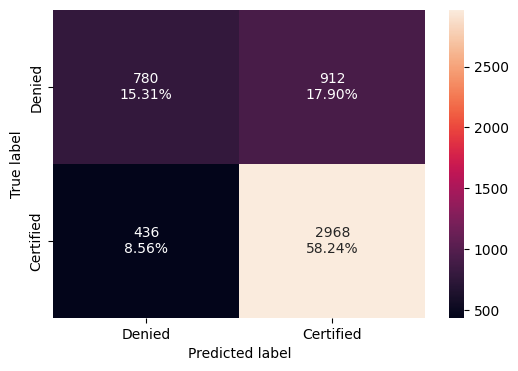

In [109]:
plot_confusion_matrix(best_model, X_test, y_test)

**Observations:**

*   The **2970 correctly predicted certified cases** indicate that the model prioritizes identifying certified visa applications correctly.
*   Only **434 certified visa applications** were **incorrectly predicted as denied** which suggests that the model minimized false negatives.
*   There are 922 false positives, denied cases incorrectly predicted as certified.




##### **Plotting feature importance**

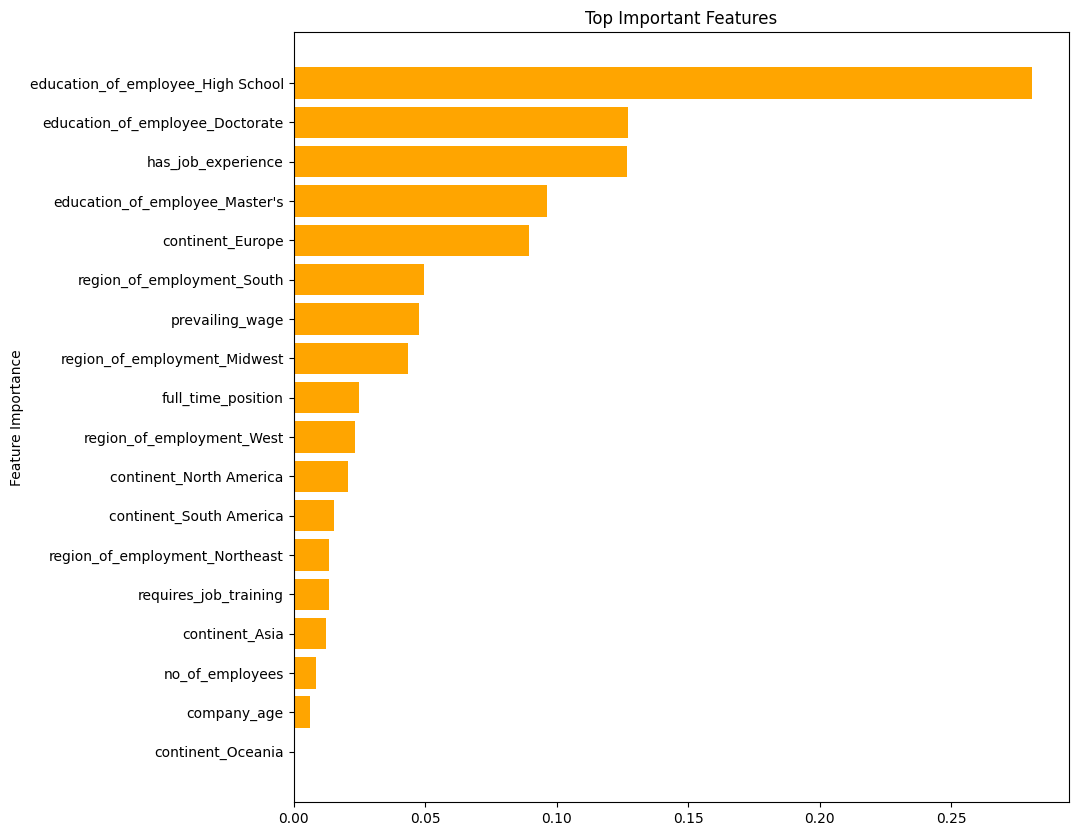

In [110]:
# Getting feature importance
feature_importance = pd.Series(
    best_model.feature_importances_, # getting feature importance
    index=X_train.columns              # setting column names as indexes
).sort_values(ascending=False)   # sort features from highest to lowest importance

# Plotting feature importance
plt.figure(figsize=(10, 10))
plt.barh(feature_importance.index, feature_importance.values, color = 'orange', align = 'center')
plt.ylabel("Feature Importance")
plt.title("Top Important Features")
plt.gca().invert_yaxis()
plt.show()

**Observations:**

*   **Education of employees** and p**rior job experience** are the **most important features** for predicting visa certification.
*   **Continent**, **employment region** and **Prevailing wage** also **contribute significantly** towards the prediction.




##**Actionable Insights & Recommendations**



**Model Performance Insights**

*   **XGBoost** model had h**ighest precision, accuracy and F1 score** while maintaining **good recall**.
*   **AdaBoost had the highest recall** but **low accuracy and precision** indicating that it was predicting almost every application as certified.
*   **Random Forest achieved balanced performance** but **not as good as achieved by XGBoost**.
*   Thus, among all the models tested, **XGBoost was chosen as the final model** as it achieved best overall performance across all metrics.








**Business Insights and Recommendations**

*   Companies should **hire employees with high education level and prior job experience** as these have higher chances of visa certification.
*   Prevailing wage and region of employment also influence visa certification suggesting **employees with high-paying jobs and region with high labor demand are more likely to get visa certification**.
*   **Full-time job offers** should also be prioritized.



